# Sesiunea 10 - Clustering: k-Means & Hierarchical

### Hands-on: Customer segmentation

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Pregatire (ruleaza o data)

Azi lucram cu:
- Date sintetice 2D, ca sa vedem clar cum functioneaza k-Means si hierarchical clustering
- **Mall_Customers.csv**, un set real cu 200 de clienti (varsta, venit anual, scor de cheltuieli), pentru segmentarea de clienti

Nu mai avem etichete (`y`). Azi algoritmul descopera singur structura din date.

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
plt.rcParams["figure.figsize"] = (8, 4.5)
np.random.seed(0)
print("gata")

gata


---
# Partea 1 - k-Means pe date sintetice

## 1 - Un exemplu jucarie, ca sa vedem algoritmul in actiune

Generam 3 grupuri de puncte 2D, clar separate, si rulam k-Means cu k=3.

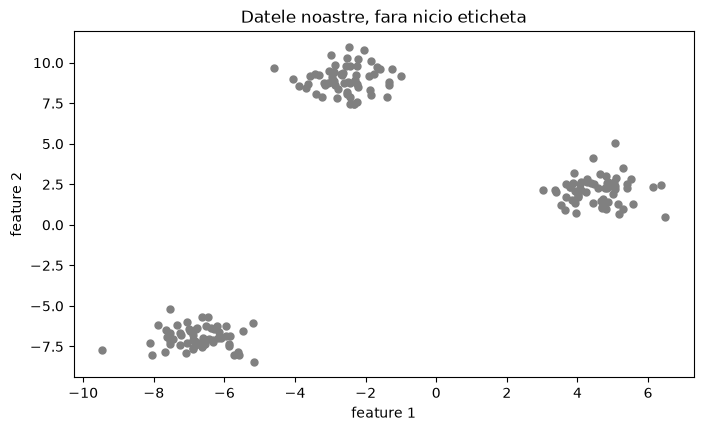

In [ ]:
X_toy, y_true_toy = make_blobs(n_samples=180, centers=3, cluster_std=0.8, random_state=42)

plt.scatter(X_toy[:, 0], X_toy[:, 1], s=25, c="gray")
plt.title("Datele noastre, fara nicio eticheta")
plt.xlabel("feature 1"); plt.ylabel("feature 2")
plt.show()

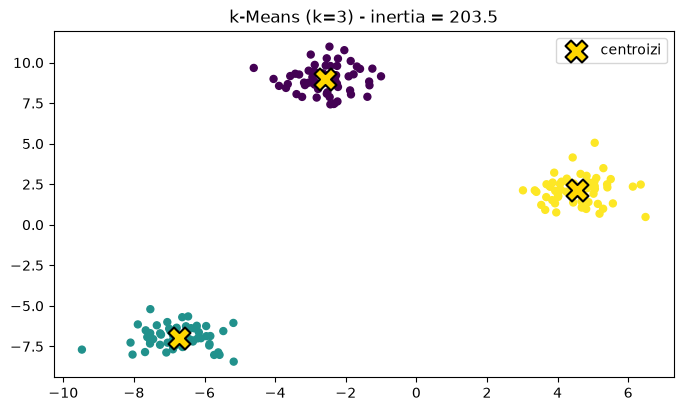

In [ ]:
km_toy = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_toy)

plt.scatter(X_toy[:, 0], X_toy[:, 1], s=25, c=km_toy.labels_, cmap="viridis")
plt.scatter(km_toy.cluster_centers_[:, 0], km_toy.cluster_centers_[:, 1],
            marker="X", s=250, c="gold", edgecolors="black", linewidths=1.5, label="centroizi")
plt.title(f"k-Means (k=3) - inertia = {km_toy.inertia_:.1f}")
plt.legend(); plt.show()

**Ce vedem:** k-Means a gasit singur cele 3 grupuri, doar din pozitia punctelor, fara sa ii spunem noi vreo eticheta. `inertia_` e suma distantelor patrate de la fiecare punct la centroidul sau, cu cat e mai mica, cu atat clusterele sunt mai compacte.

## 2 - Scenariu: ce se intampla daca alegem k gresit? 🚨

Hai sa incercam intentionat k=2 si k=6 pe aceleasi date, ca sa vedem cum arata o alegere gresita a lui k.

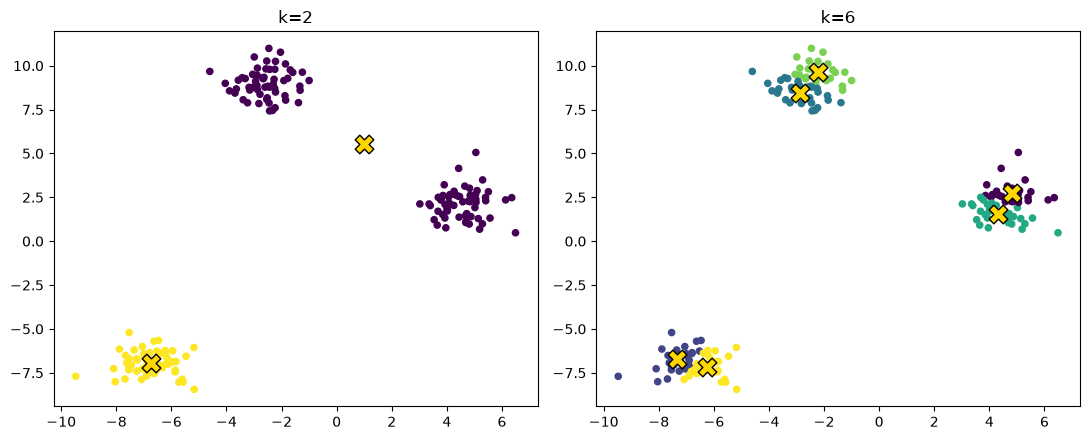

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, k in zip(axes, [2, 6]):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_toy)
    ax.scatter(X_toy[:, 0], X_toy[:, 1], s=20, c=m.labels_, cmap="viridis")
    ax.scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], marker="X", s=180, c="gold", edgecolors="black")
    ax.set_title(f"k={k}")
plt.tight_layout(); plt.show()

**Intrebare** - Uitandu-va la cele doua grafice, ce probleme observati la k=2 si la k=6?



## 3 - Terenul vostru de joaca: metoda cotului (elbow) 🎛️

Antrenam k-Means pentru mai multe valori de k si urmarim inertia. Cautam "cotul" curbei.

**Incercati:** schimbati `k_range` de mai jos (ex: adaugati k=10, 12) si vedeti daca concluzia se schimba.

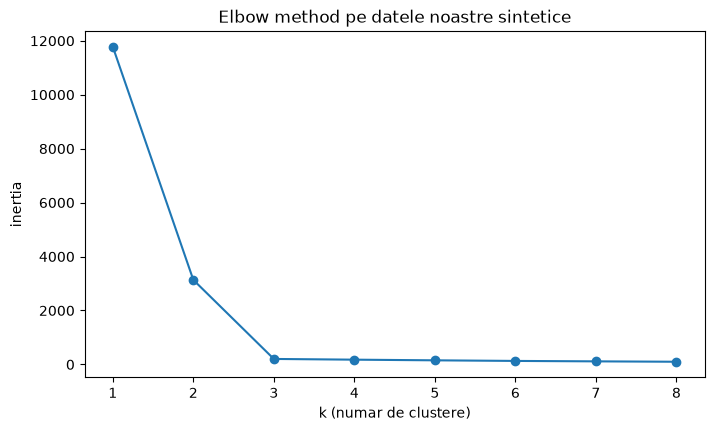

inertii: [11778.4, 3134.6, 203.5, 176.7, 152.4, 130.1, 114.2, 99.7]


In [ ]:
# MODIFICA k_range de mai jos si ruleaza din nou (Shift+Enter)
k_range = range(1, 9)
inertias = []
for k in k_range:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_toy)
    inertias.append(m.inertia_)

plt.plot(list(k_range), inertias, "o-")
plt.xlabel("k (numar de clustere)"); plt.ylabel("inertia")
plt.title("Elbow method pe datele noastre sintetice")
plt.show()
print("inertii:", [round(i, 1) for i in inertias])

Pe datele noastre sintetice (3 grupuri reale), cotul ar trebui sa apara clar la k=3: exact numarul de grupuri cu care am generat datele.

---
# Partea 2 - Capcana scalarii: de ce conteaza StandardScaler

## 4 - Scenariul flawed: clustering pe feature-uri nescalate 🚨

Construim un mini-set cu doua feature-uri pe scale foarte diferite: **venit** (zeci de mii) si **varsta** (zeci). In realitate, punctele formeaza 2 grupuri clare dupa varsta, dar venitul variaza mult mai mult numeric.

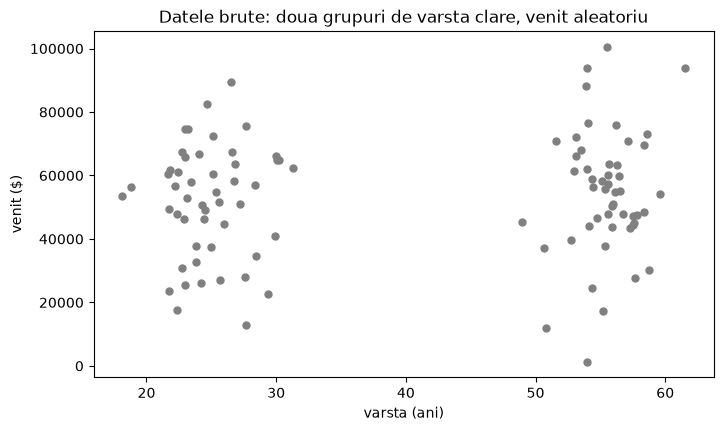

In [ ]:
np.random.seed(1)
n = 100
varsta = np.concatenate([np.random.normal(25, 3, n // 2), np.random.normal(55, 3, n // 2)])
venit  = np.random.normal(50000, 20000, n)  # venit aleatoriu, nu are legatura cu grupul

df_flawed = pd.DataFrame({"varsta": varsta, "venit": venit})
plt.scatter(df_flawed["varsta"], df_flawed["venit"], s=25, c="gray")
plt.xlabel("varsta (ani)"); plt.ylabel("venit ($)")
plt.title("Datele brute: doua grupuri de varsta clare, venit aleatoriu")
plt.show()

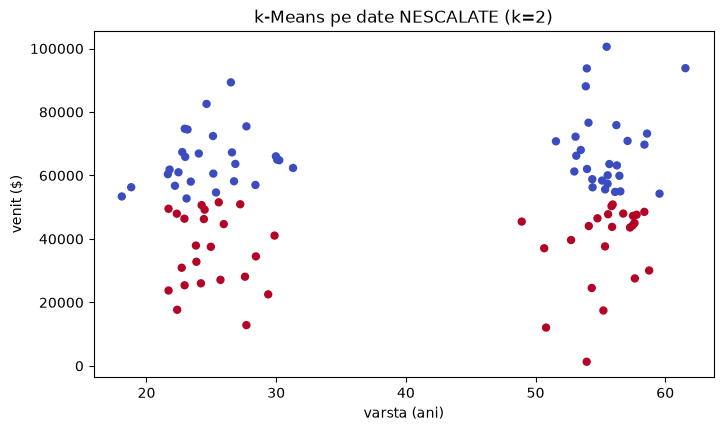

In [ ]:
km_flawed = KMeans(n_clusters=2, n_init=10, random_state=0).fit(df_flawed[["varsta", "venit"]])

plt.scatter(df_flawed["varsta"], df_flawed["venit"], s=25, c=km_flawed.labels_, cmap="coolwarm")
plt.xlabel("varsta (ani)"); plt.ylabel("venit ($)")
plt.title("k-Means pe date NESCALATE (k=2)")
plt.show()

**Ce s-a intamplat?** Uitati-va la grafic: clusterele NU coincid cu cele doua grupuri de varsta pe care le vedem cu ochiul liber. Pentru ca venitul are valori de ordinul zecilor de mii, iar varsta de ordinul zecilor, distanta euclidiana e dominata aproape complet de venit, iar k-Means grupeaza in functie de venit (aleatoriu), nu de varsta (structura reala).

Un semn clar al problemei este ca **un cluster domina / clustere fara sens**, ceea ce indica faptul ca feature-urile nu sunt scalate corespunzator.

## 5 - Exercitiu ghidat: diagnosticheaza si repara cu StandardScaler

Rezolvarea e sa **standardizam** feature-urile (medie 0, deviatie standard 1) inainte de clustering, ca niciuna sa nu domine doar din cauza unitatii de masura.

Completeaza codul de mai jos (inlocuieste liniile cu `# ...`):
1. Creeaza un `StandardScaler()` si aplica-l pe `df_flawed[["varsta", "venit"]]`
2. Ruleaza `KMeans(n_clusters=2, ...)` pe datele scalate
3. Deseneaza scatter-ul, colorat dupa noile etichete

In [ ]:
scaler = # ...
X_scaled = # ...   # fit_transform pe df_flawed[["varsta", "venit"]]

km_fixed = # ...   # KMeans(n_clusters=2, ...) pe X_scaled

plt.scatter(df_flawed["varsta"], df_flawed["venit"], s=25, c=km_fixed.labels_, cmap="coolwarm")
plt.xlabel("varsta (ani)"); plt.ylabel("venit ($)")
plt.title("k-Means pe date SCALATE (k=2)")
plt.show()

SyntaxError: invalid syntax (2732754745.py, line 1)

---
# Partea 3 - Hierarchical Clustering

## 6 - Construim o dendrograma

Folosim `scipy.cluster.hierarchy.linkage`, cu `method="ward"` pentru a combina clusterele in functie de similaritate.

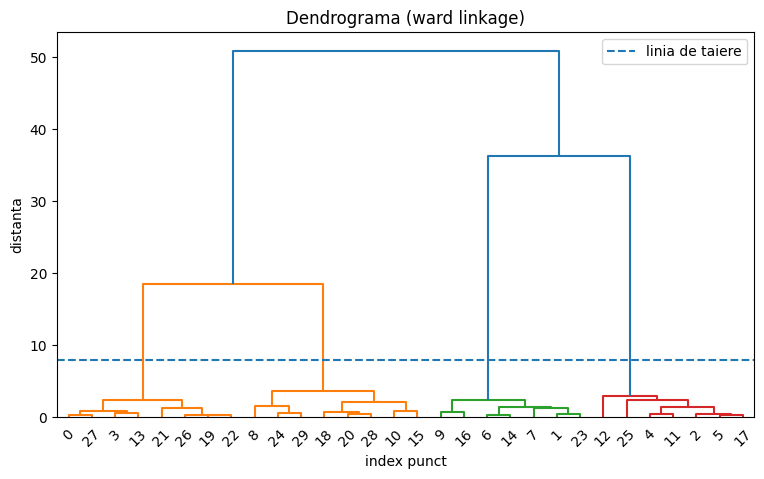

In [ ]:
X_small, _ = make_blobs(n_samples=30, centers=4, cluster_std=0.7, random_state=7)

Z = linkage(X_small, method="ward")

plt.figure(figsize=(9, 5))
dendrogram(Z)
plt.axhline(y=8, color="tab:blue", linestyle="--", label="linia de taiere")
plt.title("Dendrograma (ward linkage)")
plt.xlabel("index punct"); plt.ylabel("distanta")
plt.legend(); plt.show()

**Exercitiu ghidat** - Taiati dendrograma la doua inaltimi diferite si vedeti cate clustere obtineti la fiecare. Folositi `fcluster(Z, t=<inaltime>, criterion="distance")`.

Taiere la inaltime 15 -> 4 clustere
Taiere la inaltime 5  -> 4 clustere


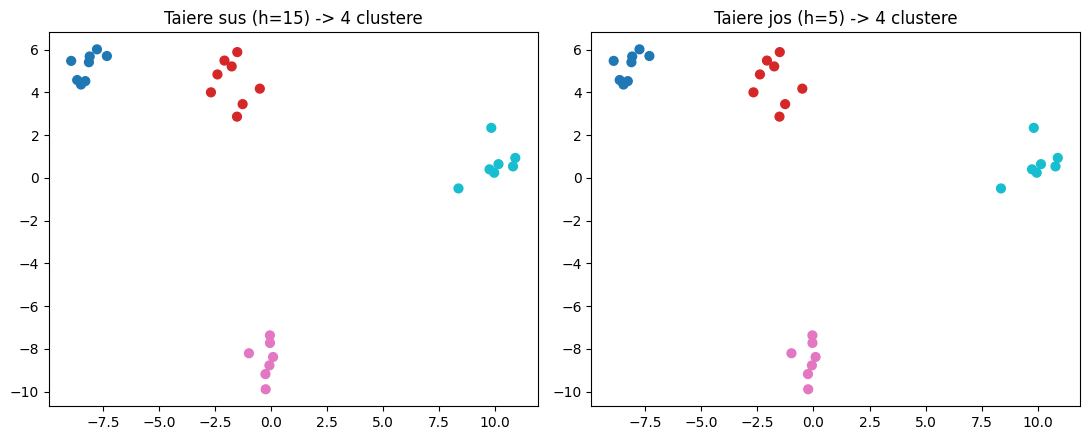

In [ ]:
labels_high = # ...   # fcluster(Z, t=15, criterion="distance")
labels_low  = # ...   # fcluster(Z, t=5, criterion="distance")

print(f"Taiere la inaltime 15 -> {len(set(labels_high))} clustere")
print(f"Taiere la inaltime 5  -> {len(set(labels_low))} clustere")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X_small[:, 0], X_small[:, 1], c=labels_high, cmap="tab10", s=40)
axes[0].set_title(f"Taiere sus (h=15) -> {len(set(labels_high))} clustere")
axes[1].scatter(X_small[:, 0], X_small[:, 1], c=labels_low, cmap="tab10", s=40)
axes[1].set_title(f"Taiere jos (h=5) -> {len(set(labels_low))} clustere")
plt.tight_layout(); plt.show()

**Scenariu** - Aveti 50.000 de puncte de date. Vreti sa faceti o dendrograma completa pe toate?

---
# Partea 4 - Hands-on: Customer segmentation (date reale)

## 7 - Incarcam si exploram datele

`Mall_Customers.csv`: 200 de clienti ai unui mall, cu varsta, gen, venit anual si un scor de cheltuieli (1-100, calculat de mall pe baza comportamentului de cumparare).

In [3]:
import pandas as pd

df = pd.read_csv("Mall_Customers.csv")
print(df.shape)
df.head()

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


**Intrebare** - Uitandu-va la `describe()`, ce observati despre scala celor doua coloane pe care le vom folosi (`Annual Income (k$)` si `Spending Score (1-100)`)?


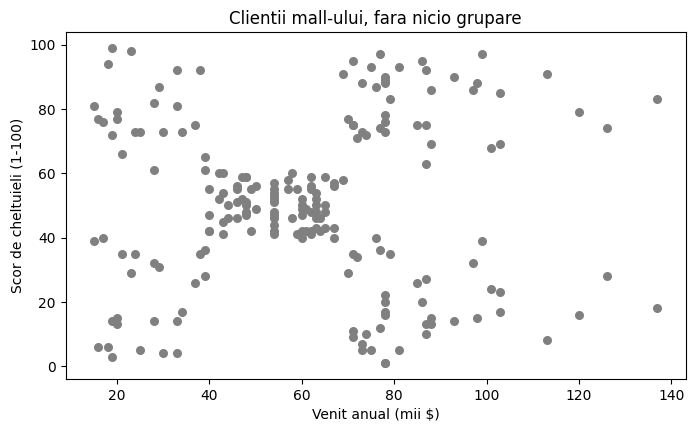

In [ ]:
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], s=30, c="gray")
plt.xlabel("Venit anual (mii $)"); plt.ylabel("Scor de cheltuieli (1-100)")
plt.title("Clientii mall-ului, fara nicio grupare")
plt.show()

## 8 - Exercitiu ghidat: scalam, alegem k prin elbow, si clusterizam

Completeaza codul de mai jos:
1. Extrage `X = df[["Annual Income (k$)", "Spending Score (1-100)"]]`
2. Scaleaza cu `StandardScaler`
3. Calculeaza inertia pentru k=1..9 si afiseaza graficul elbow

In [ ]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = # ...

scaler_mall = # ...
X_scaled_mall = # ...   # fit_transform pe X

inertias_mall = []
for k in range(1, 10):
    m = # ...   # KMeans(n_clusters=k, ...) pe X_scaled_mall
    inertias_mall.append(m.inertia_)

plt.plot(range(1, 10), inertias_mall, "o-")
plt.xlabel("k"); plt.ylabel("inertia")
plt.title("Elbow method - Mall Customers")
plt.show()
print([round(i, 1) for i in inertias_mall])

NameError: name 'df' is not defined

Acum rulam k-Means cu k=5 (ales prin elbow) si adaugam eticheta de cluster in DataFrame.

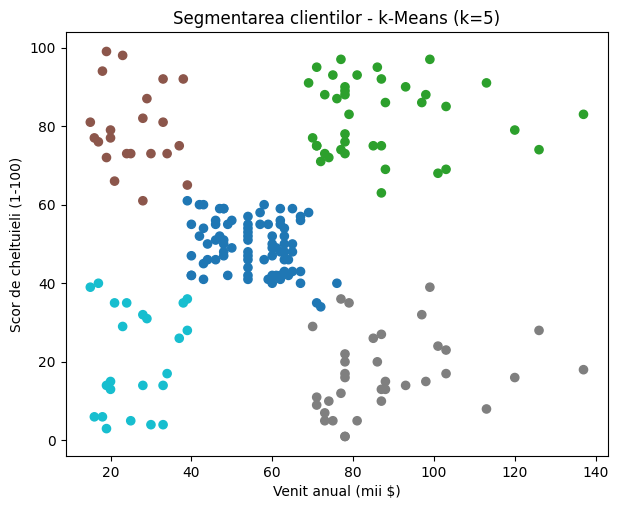

,Annual Income (k$),Spending Score (1-100)
cluster,,
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


In [ ]:
kmeans_mall = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_scaled_mall)
df["cluster"] = kmeans_mall.labels_

plt.figure(figsize=(7, 5.5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], c=df["cluster"], cmap="tab10", s=35)
plt.xlabel("Venit anual (mii $)"); plt.ylabel("Scor de cheltuieli (1-100)")
plt.title("Segmentarea clientilor - k-Means (k=5)")
plt.show()

df.groupby("cluster")[features].mean().round(1)

## 9 - Exercitiu independent: dati nume de business fiecarui cluster 🔍

Acum lucrati singuri. Pe baza statisticilor din tabelul de mai sus (`groupby("cluster")[features].mean()`) si a graficului, dati **fiecarui cluster** un nume de business scurt (ex: "Premium", "Econom" etc.) si o propozitie care explica de ce.

**Cerinte:**
1. Pentru fiecare din cele 5 clustere, afiseaza venitul mediu, scorul mediu de cheltuieli si numarul de clienti (`n`).
2. Scrie, intr-un dictionar `nume_clustere = {0: "...", 1: "...", ...}`, un nume de business pentru fiecare id de cluster.
3. **Bonus:** adauga si `Age` in clustering (reia pasii de scalare + KMeans cu 3 feature-uri) si vezi daca segmentele se schimba semnificativ fata de varianta cu doar 2 feature-uri.

In [ ]:
# Scrie codul tau aici
# stats = df.groupby("cluster")[features + ["Age"]].agg(["mean", "count"])
# nume_clustere = {0: "...", 1: "...", 2: "...", 3: "...", 4: "..."}


## 10 - Scenariu final: ce faceti cu segmentele astea? 🤔

Pentru fiecare grup de mai jos, ganditi-va la o actiune de marketing potrivita:

1. Clientii cu venit mare si cheltuieli mari ("Premium")
2. Clientii cu venit mare dar cheltuieli mici ("Precauti")
3. Clientii cu venit mic dar cheltuieli mari ("Impulsivi")

## Recap

Am parcurs doua metode de clustering si o aplicatie completa:

**k-Means**
- Alegem k, asignam puncte la cel mai apropiat centroid, recalculam, repetam
- Alegem k cu metoda cotului (elbow), uitandu-ne unde inertia se aplatizeaza
- Rapid, dar presupune clustere aproximativ sferice

**Hierarchical Clustering**
- Construim un arbore de fuziuni de jos in sus (linkage)
- Alegem k **dupa**, taind dendrograma la o anumita inaltime
- Bun pentru explorare pe seturi mici/medii, mai lent pe seturi mari

**Cea mai importanta lectie practica**
- Scalarea feature-urilor (`StandardScaler`) e aproape mereu obligatorie inainte de clustering, altfel o singura variabila cu valori mari domina toata distanta

**Segmentarea clientilor**
- Am gasit 5 segmente reale in `Mall_Customers.csv` pe baza de venit si cheltuieli
- Clusterele matematice capata sens de business doar dupa ce noi le interpretam si le dam un nume

Pe scurt: clusteringul gaseste structura acolo unde nu exista niciun raspuns corect dat dinainte, doar similaritate intre puncte, iar interpretarea ramane treaba noastra.